In [1]:
%pip install -q ultralytics==8.4.216 PyYAML

Note: you may need to restart the kernel to use updated packages.


## 1. Check the GPU and choose your run

In [11]:
from collections import Counter
from pathlib import Path
import csv
import math
import random
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from matplotlib.patches import Rectangle
import torch
import ultralytics
import yaml
from ultralytics import YOLO

RUN_MODE = "full"  # "smoke" or "full"
IMAGE_SIZE = 640
BATCH = 8
SEED = 42
DATASET_SLUG = "construction-site-safety-image-dataset-roboflow"
INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working")
WEIGHTS = WORK / "yolo11n.pt"

run_settings = {"smoke": (1, 0.10), "full": (10, 1.0)}
if RUN_MODE not in run_settings:
    raise ValueError(f"Choose RUN_MODE from {list(run_settings)}")
EPOCHS, TRAIN_FRACTION = run_settings[RUN_MODE]

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
if not torch.cuda.is_available():
    raise RuntimeError("Enable a GPU accelerator in Kaggle Settings and rerun this cell.")
DEVICE = 0
print("GPU:", torch.cuda.get_device_name(DEVICE))

PyTorch: 2.11.0+cu130
Ultralytics: 8.4.216
GPU: Tesla T4


## 2. Locate the dataset and create the training YAML

In [12]:
split_folders = {"train": "train", "val": "valid", "test": "test"}
mounts = sorted(INPUT.rglob(DATASET_SLUG))
mounts = [folder for folder in mounts if folder.is_dir()]
search_roots = mounts or [INPUT]
candidates = sorted({
    folder
    for mount in search_roots
    for folder in [mount, *mount.rglob("css-data")]
    if all((folder / split / kind).is_dir()
           for split in split_folders.values()
           for kind in ("images", "labels"))
})
if len(candidates) != 1:
    raise FileNotFoundError(
        f"Expected one copy of the construction dataset. Found {candidates}. "
        "Attach the dataset listed at the top of the notebook."
    )
DATA_ROOT = candidates[0]
split_dirs = {key: DATA_ROOT / folder for key, folder in split_folders.items()}
source_yaml = DATA_ROOT / "data.yaml"
if source_yaml.is_file():
    raw_names = yaml.safe_load(source_yaml.read_text(encoding="utf-8"))["names"]
    if isinstance(raw_names, dict):
        names_by_id = {int(key): value for key, value in raw_names.items()}
        CLASS_NAMES = [names_by_id[index] for index in range(len(names_by_id))]
    else:
        CLASS_NAMES = list(raw_names)
else:
    CLASS_NAMES = [
        "Hardhat", "Mask", "NO-Hardhat", "NO-Mask", "NO-Safety Vest",
        "Person", "Safety Cone", "Safety Vest", "machinery", "vehicle",
    ]

DATA_YAML = WORK / "construction_data.yaml"
data_config = {
    "path": str(DATA_ROOT),
    **{key: str(folder / "images") for key, folder in split_dirs.items()},
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}
DATA_YAML.write_text(yaml.safe_dump(data_config, sort_keys=False), encoding="utf-8")
print(DATA_YAML.read_text())

path: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data
train: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/train/images
val: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/valid/images
test: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/test/images
nc: 10
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle



## 3. Check the annotations and draw ground-truth boxes

In [13]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def read_labels(label_path):
    rows = []
    for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), 1):
        if not line.strip():
            continue
        try:
            class_id, x, y, width, height = map(float, line.split())
        except ValueError as error:
            raise ValueError(f"Invalid YOLO row at {label_path}:{line_number}") from error
        if (
            not math.isfinite(class_id)
            or not class_id.is_integer()
            or not 0 <= class_id < len(CLASS_NAMES)
            or not all(0 <= value <= 1 for value in (x, y, width, height))
            or min(width, height) <= 0
        ):
            raise ValueError(f"Invalid class or coordinates at {label_path}:{line_number}")
        rows.append((int(class_id), x, y, width, height))
    return rows

images = {}
annotations = {}
split_summary = []
class_counts = {}
for split, directory in split_dirs.items():
    images[split] = sorted(
        file for file in (directory / "images").iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )
    if not images[split]:
        raise FileNotFoundError(f"No images in {directory / 'images'}")
    annotation_files = {file.stem: file for file in (directory / "labels").glob("*.txt")}
    image_stems = {file.stem for file in images[split]}
    orphan_labels = annotation_files.keys() - image_stems
    if orphan_labels:
        raise ValueError(f"{split}: {len(orphan_labels)} labels have no matching image")

    annotations[split] = {}
    for image_path in images[split]:
        label = annotation_files.get(image_path.stem)
        annotations[split][image_path] = read_labels(label) if label else []

    class_counts[split] = Counter(
        row[0] for rows in annotations[split].values() for row in rows
    )
    if not class_counts[split]:
        raise ValueError(f"{split}: no bounding boxes found")
    split_summary.append({
        "split": split,
        "images": len(images[split]),
        "images with boxes": sum(bool(rows) for rows in annotations[split].values()),
        "missing label files": sum(file.stem not in annotation_files for file in images[split]),
        "empty label files": sum(
            not rows and file.stem in annotation_files
            for file, rows in annotations[split].items()
        ),
        "boxes": sum(class_counts[split].values()),
    })

display(pd.DataFrame(split_summary).set_index("split"))
display(pd.DataFrame({
    split: [counts[index] for index in range(len(CLASS_NAMES))]
    for split, counts in class_counts.items()
}, index=CLASS_NAMES))

,images,images with boxes,missing label files,empty label files,boxes
split,,,,,
train,2605,2599,0,6,36895
val,114,104,0,10,697
test,82,74,0,8,760


,train,val,test
Hardhat,3145,79,110
Mask,1651,21,28
NO-Hardhat,2317,69,41
NO-Mask,3097,74,79
NO-Safety Vest,3962,106,90
Person,9532,166,174
Safety Cone,3366,44,92
Safety Vest,3033,41,61
machinery,5247,55,44
vehicle,1545,42,41


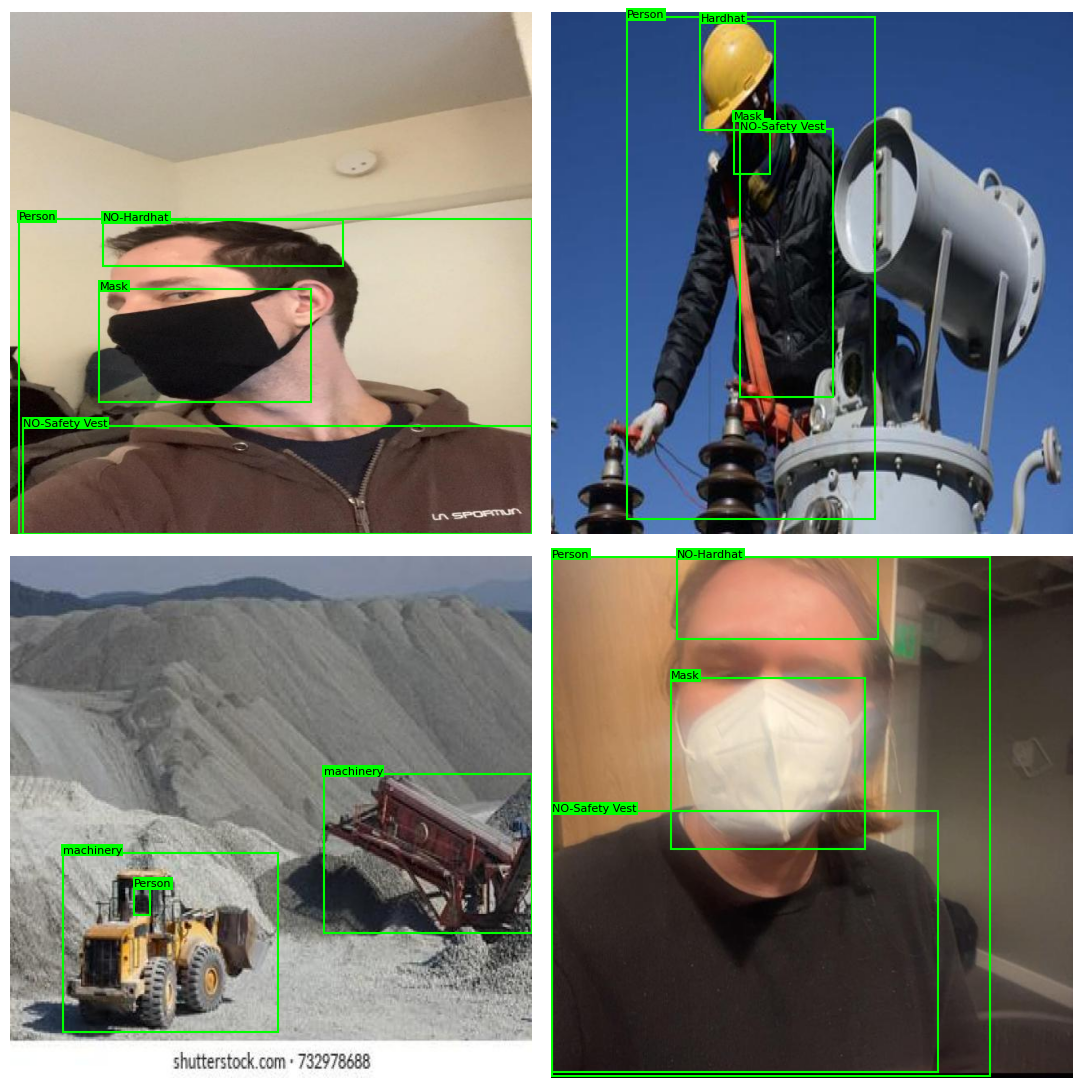

In [14]:
def show_ground_truth(axis, image_path, rows):
    with Image.open(image_path) as image:
        axis.imshow(image.convert("RGB"))
        pixel_width, pixel_height = image.size
    for class_id, x, y, width, height in rows:
        left = (x - width / 2) * pixel_width
        top = (y - height / 2) * pixel_height
        axis.add_patch(Rectangle(
            (left, top), width * pixel_width, height * pixel_height,
            fill=False, edgecolor="lime", linewidth=1.5,
        ))
        axis.text(left, top, CLASS_NAMES[class_id], color="black", fontsize=8,
                  bbox={"facecolor": "lime", "edgecolor": "none", "pad": 1})
    axis.axis("off")

preview_examples = [
    path for path in images["val"] if 1 <= len(annotations["val"][path]) <= 6
]
samples = random.Random(SEED).sample(preview_examples, min(4, len(preview_examples)))
fig, axes = plt.subplots(2, 2, figsize=(11, 11))
for axis in axes.flat:
    axis.axis("off")
for axis, image_path in zip(axes.flat, samples):
    show_ground_truth(axis, image_path, annotations["val"][image_path])
plt.tight_layout()
plt.show()

## 4. Fine-tune YOLO11n

In [15]:
model = YOLO(str(WEIGHTS))
model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    fraction=TRAIN_FRACTION,
    imgsz=IMAGE_SIZE,
    batch=BATCH,
    device=DEVICE,
    workers=2,
    seed=SEED,
    project=str(WORK / "ppe_training"),
    name=RUN_MODE,
    plots=True,
)

RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(f"Training did not produce {BEST_WEIGHTS}")
print("Best checkpoint:", BEST_WEIGHTS)
history = pd.read_csv(RUN_DIR / "results.csv")
history.columns = history.columns.str.strip()
display(history.tail())

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/construction_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=full, nbs=64, nms=None, opset=None

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
5,6,274.159,1.24494,1.25631,1.35908,0.77477,0.55157,0.62970,0.28369,1.89445,1.37707,1.77481,0.000361,0.000361,0.000361
6,7,308.801,1.20983,1.17147,1.33110,0.79252,0.58733,0.65727,0.31163,1.81590,1.26029,1.74579,0.000290,0.000290,0.000290
7,8,343.285,1.17603,1.11801,1.30941,0.74519,0.63002,0.67027,0.34794,1.65130,1.14175,1.61866,0.000219,0.000219,0.000219
8,9,378.084,1.14137,1.04661,1.28240,0.82711,0.62966,0.70665,0.35985,1.67327,1.10388,1.61059,0.000149,0.000149,0.000149
9,10,412.869,1.12211,1.00728,1.26869,0.81658,0.63693,0.69935,0.37326,1.64426,1.05895,1.60519,0.000078,0.000078,0.000078


## 5. Evaluate and read the results

In [16]:
RUN_FINAL_TEST = False
detector = YOLO(str(BEST_WEIGHTS))

evaluation_splits = ["val"]
if RUN_MODE == "full" and RUN_FINAL_TEST:
    evaluation_splits.append("test")

metric_rows = []
for split in evaluation_splits:
    metrics = detector.val(
        data=str(DATA_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH,
        device=DEVICE, workers=2, plots=True,
        project=str(RUN_DIR / "evaluation"), name=split,
    )
    metric_rows.append({
        "split": split,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
    })

metric_table = pd.DataFrame(metric_rows).set_index("split")
display(metric_table.round(4))
metric_table.to_csv(RUN_DIR / "evaluation_metrics.csv")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 108.7±18.0 MB/s, size: 61.4 KB)
val: Scanning /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/valid/labels... 114 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114 694.2it/s 0.2ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.6it/s 2.0s<0.1s
                   all        114        697      0.816      0.637        0.7      0.373
               Hardhat         42         79      0.885       0.78      0.827      0.472
                  Mask         19         21        0.9       0.81      

,precision,recall,mAP50,mAP50-95
split,,,,
val,0.8159,0.6369,0.7005,0.3725


## 6. Compare predictions with labels on validation images

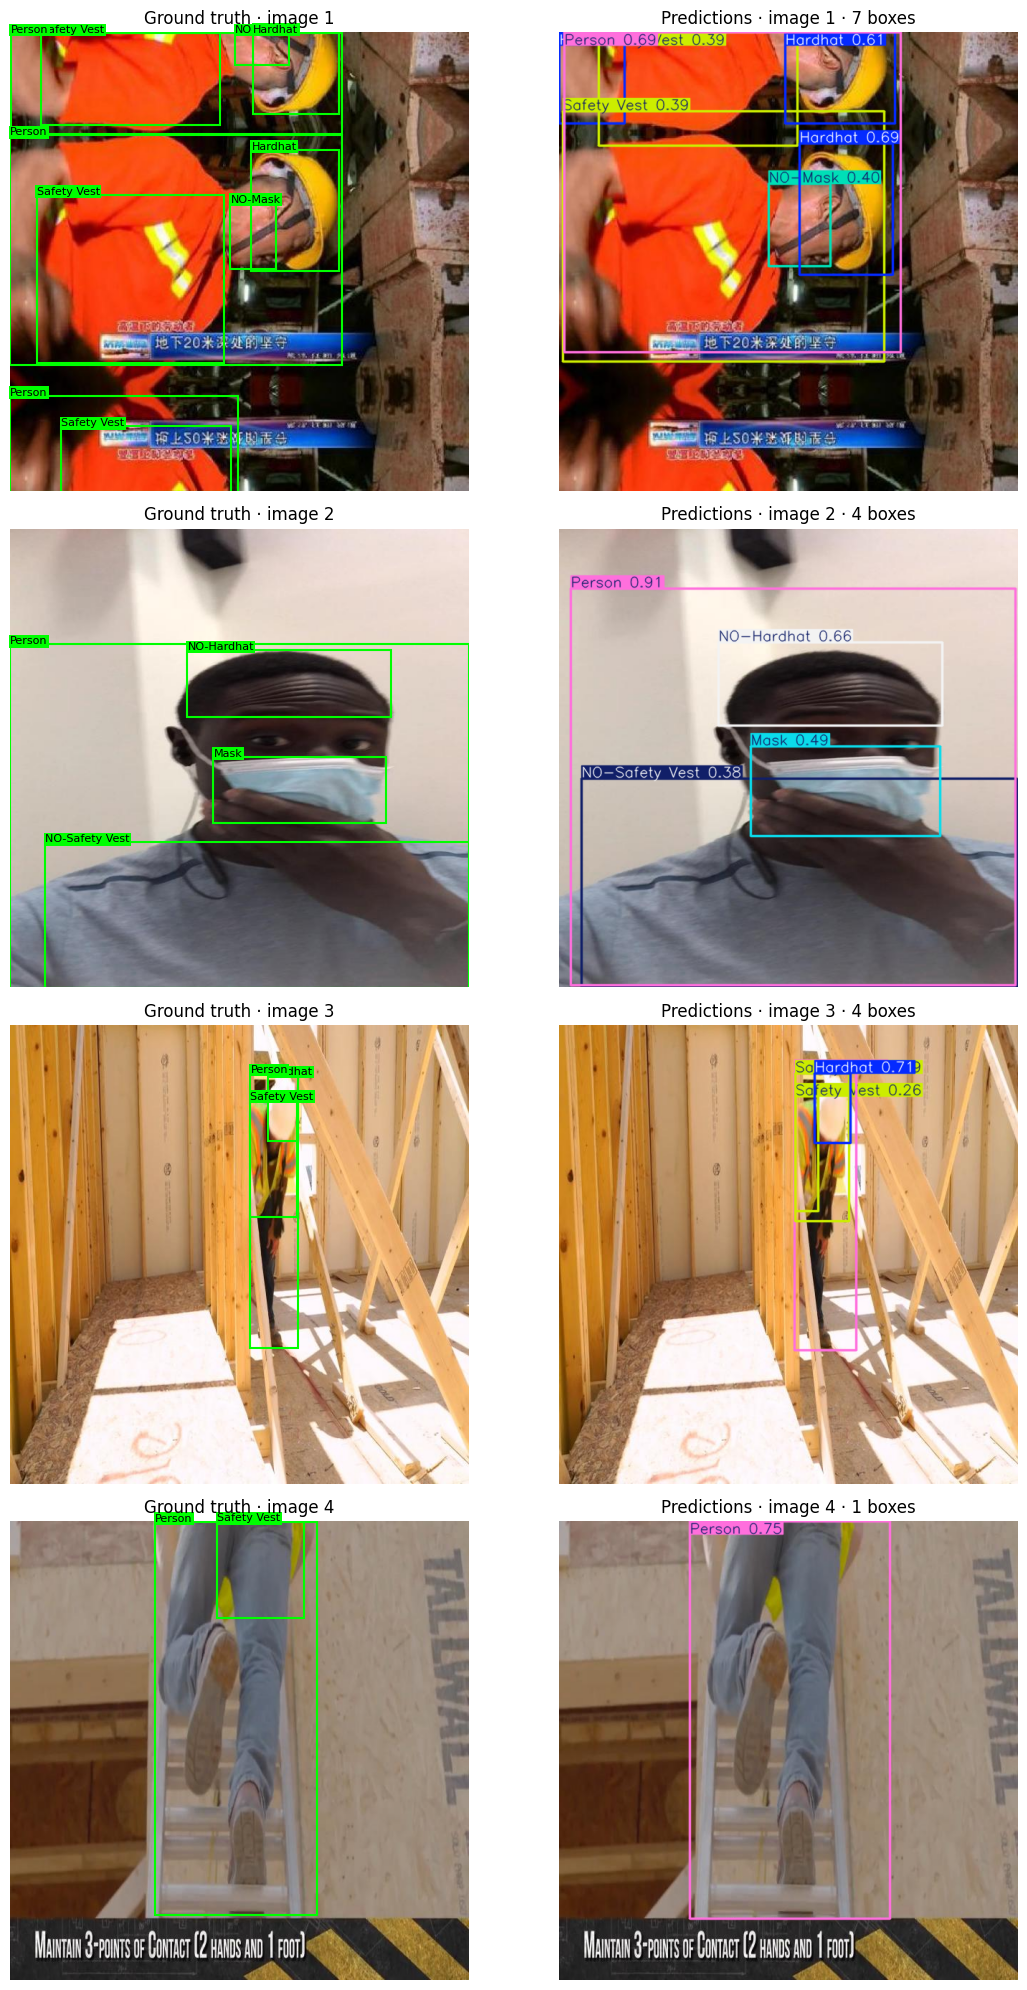

In [17]:
CONFIDENCE = 0.25
validation_samples = random.Random(SEED + 1).sample(images["val"], min(4, len(images["val"])))
predictions = detector.predict(
    source=[str(path) for path in validation_samples],
    imgsz=IMAGE_SIZE, conf=CONFIDENCE, device=DEVICE, verbose=False,
)

prediction_dir = RUN_DIR / "predictions"
prediction_dir.mkdir(exist_ok=True)
rows = []
fig, axes = plt.subplots(len(predictions), 2, figsize=(12, len(predictions) * 5), squeeze=False)
for row_index, (path, prediction) in enumerate(zip(validation_samples, predictions), 1):
    truth_axis, pred_axis = axes[row_index - 1]
    show_ground_truth(truth_axis, path, annotations["val"][path])
    truth_axis.set_title(f"Ground truth · image {row_index}")

    rgb_prediction = prediction.plot()[..., ::-1]
    Image.fromarray(rgb_prediction).save(prediction_dir / f"example_{row_index}.jpg")
    pred_axis.imshow(rgb_prediction)
    pred_axis.set_title(f"Predictions · image {row_index} · {len(prediction.boxes)} boxes")
    pred_axis.axis("off")

    coords = prediction.boxes.xyxy.cpu().tolist()
    scores = prediction.boxes.conf.cpu().tolist()
    classes = prediction.boxes.cls.int().cpu().tolist()
    for box, score, class_id in zip(coords, scores, classes):
        rows.append([path.name, prediction.names[class_id], score, *box])

plt.tight_layout()
plt.show()
with (prediction_dir / "detections.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["image", "class", "confidence", "x_min", "y_min", "x_max", "y_max"])
    writer.writerows(rows)

## 7. Save the model and results

In [18]:
bundle = WORK / f"ppe_yolo11n_{RUN_DIR.name}.zip"
with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.write(BEST_WEIGHTS, "best.pt")
    archive.write(DATA_YAML, DATA_YAML.name)
    for filename in ("results.csv", "results.png", "evaluation_metrics.csv", "args.yaml"):
        artifact = RUN_DIR / filename
        if artifact.is_file():
            archive.write(artifact, filename)
    for file in sorted(prediction_dir.iterdir()):
        if file.is_file():
            archive.write(file, file.relative_to(RUN_DIR))
print("Download:", bundle)

Download: /kaggle/working/ppe_yolo11n_full.zip
